### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [2]:
monety_szare = cv2.imread('Monety_szare.bmp')
monety_szum = cv2.imread('Monety_szare_szum.bmp')

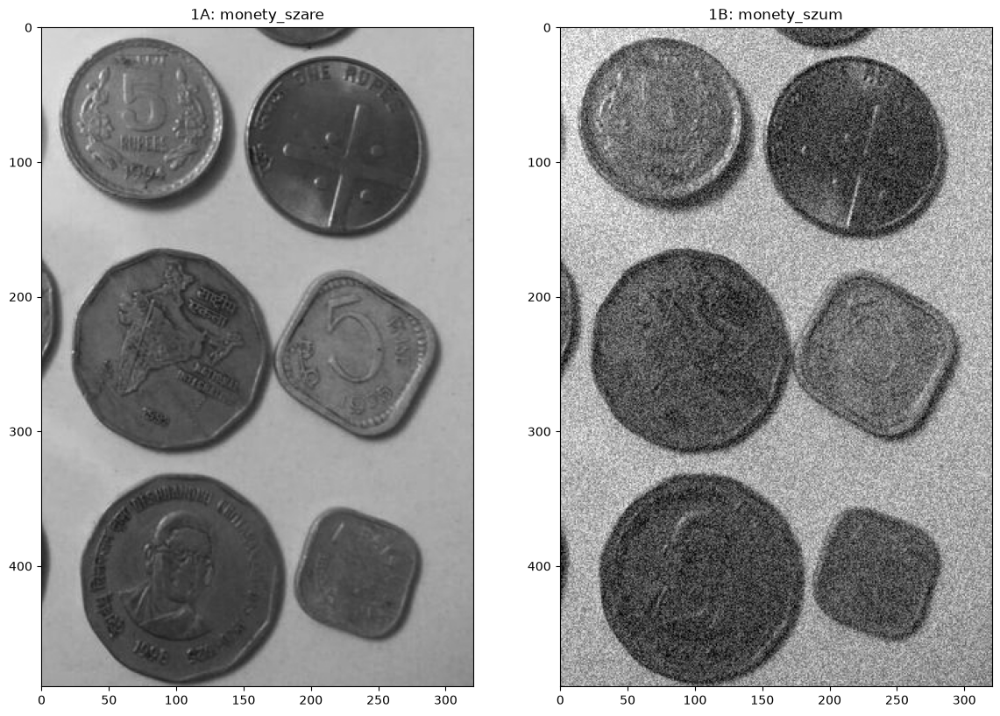

In [3]:
_, (a, b) = plt.subplots(1,2, figsize=(14,10))
a.imshow(monety_szare); a.title.set_text('1A: monety_szare')
b.imshow(monety_szum); b.title.set_text('1B: monety_szum')

Rozwiązanie części 1A:

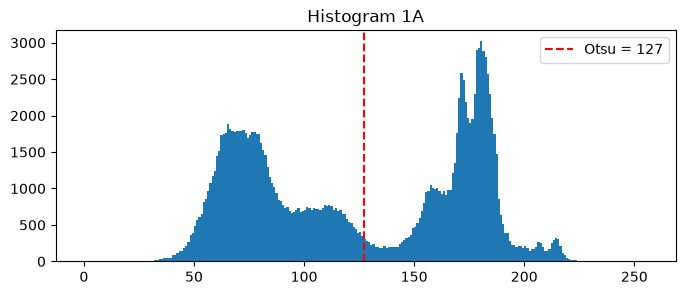

In [4]:
gray = cv2.cvtColor(monety_szare, cv2.COLOR_BGR2GRAY)

def count_objects(mask, min_area=500):
    stats = cv2.connectedComponentsWithStats(mask)[2]
    return int((stats[1:, cv2.CC_STAT_AREA] >= min_area).sum())

t_otsu, mask_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
plt.figure(figsize=(8, 3)); plt.hist(gray.ravel(), 256, range=(0, 256))
plt.axvline(t_otsu, color='r', ls='--', label=f'Otsu = {t_otsu:.0f}'); plt.legend(); plt.title('Histogram 1A'); plt.show()

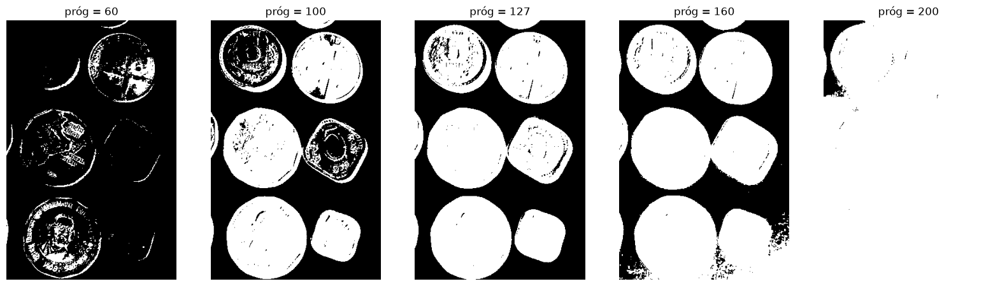

In [5]:
thresholds = [60, 100, 127, 160, 200]
_, axes = plt.subplots(1, len(thresholds), figsize=(20, 6))
for ax, t in zip(axes, thresholds):
    _, mask = cv2.threshold(gray, t, 255, cv2.THRESH_BINARY_INV)
    ax.imshow(mask, cmap='gray'); ax.set_title(f'próg = {t}'); ax.axis('off')
plt.show()

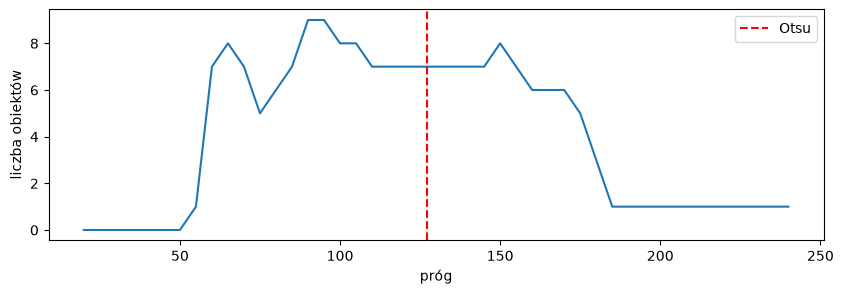

In [6]:
sweep = np.arange(20, 241, 5)
plt.figure(figsize=(10, 3))
plt.plot(sweep, [count_objects(cv2.threshold(gray, t, 255, cv2.THRESH_BINARY_INV)[1]) for t in sweep])
plt.axvline(t_otsu, color='r', ls='--', label='Otsu')
plt.xlabel('próg'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

**Wnioski:**
- za niski próg (< 60): prawie nic nie jest obiektem, przy 60-100 monety są "dziurawe" i liczba obiektów skacze,
- za wysoki próg (> 160): do obiektu wchodzi tło (cienie), monety się zlewają, przy > 180 wszystko to jeden obiekt,
- dla progów 110-145 wynik jest stabilny (7 obiektów); Otsu (127) leży w dolinie histogramu, w środku tego przedziału,
- 7 zamiast 8, bo duża i kwadratowa moneta stykają się - sam próg tego nie rozdzieli

Rozwiązanie części 1B:


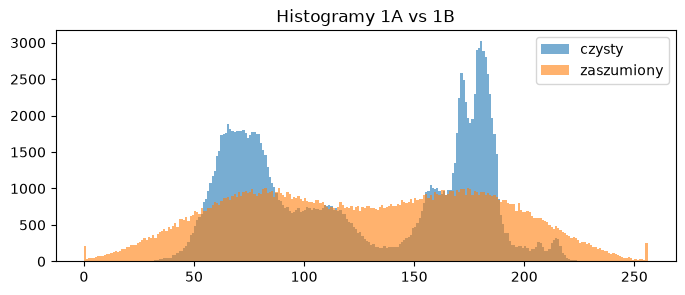

In [7]:
noisy = cv2.cvtColor(monety_szum, cv2.COLOR_BGR2GRAY)

def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / (a | b).sum()

def otsu_inv(img):
    return cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(8, 3))
plt.hist(gray.ravel(), 256, range=(0, 256), alpha=0.6, label='czysty')
plt.hist(noisy.ravel(), 256, range=(0, 256), alpha=0.6, label='zaszumiony')
plt.legend(); plt.title('Histogramy 1A vs 1B'); plt.show()

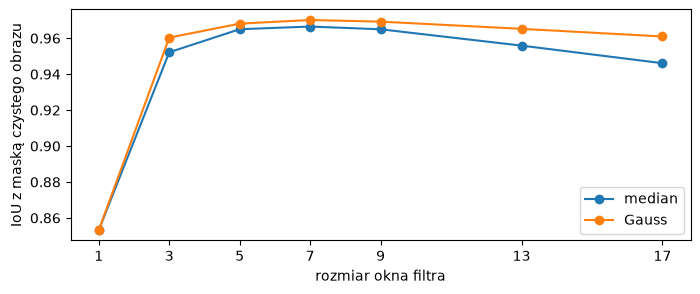

In [ ]:
kernel_sizes = [1, 3, 5, 7, 9, 13, 17]
iou_median = [iou(otsu_inv(cv2.medianBlur(noisy, k))[1], mask_otsu) for k in kernel_sizes]
iou_gauss = [iou(otsu_inv(cv2.GaussianBlur(noisy, (k, k), 0))[1], mask_otsu) for k in kernel_sizes]
plt.figure(figsize=(8, 3))
plt.plot(kernel_sizes, iou_median, 'o-', label='median'); plt.plot(kernel_sizes, iou_gauss, 'o-', label='Gauss')
plt.xticks(kernel_sizes); plt.xlabel('rozmiar okna filtra'); plt.ylabel('IoU z maską czystego obrazu'); plt.legend(); plt.show()

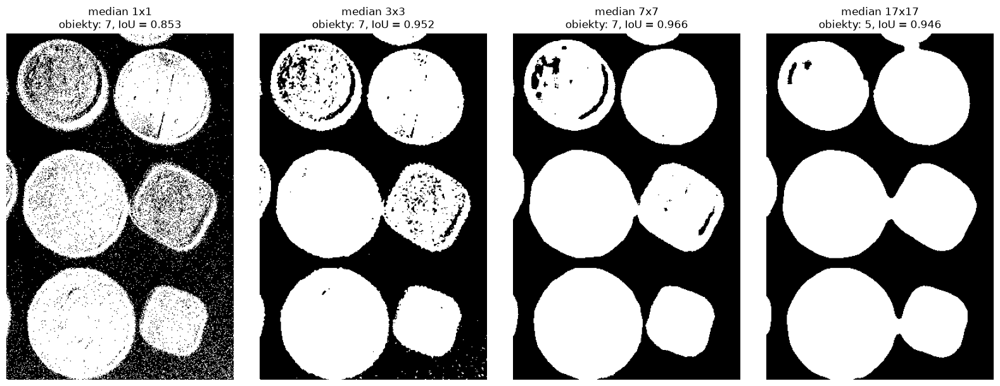

In [9]:
filters = {
    'median': lambda img, k: cv2.medianBlur(img, k),
    'Gauss': lambda img, k: cv2.GaussianBlur(img, (k, k), 0),
}
shown_sizes = [1, 3, 7, 17]
def show_filtered_masks(name):
    """Maski po filtrze `name` dla kilku rozmiarów okna."""
    _, axes = plt.subplots(1, len(shown_sizes), figsize=(4 * len(shown_sizes), 6), constrained_layout=True)
    for ax, k in zip(axes, shown_sizes):
        t, mask = otsu_inv(filters[name](noisy, k))
        ax.imshow(mask, cmap='gray'); ax.set_title(f'{name} {k}x{k}\nobiekty: {count_objects(mask)}, IoU = {iou(mask, mask_otsu):.3f}'); ax.axis('off')
    plt.show()

show_filtered_masks('median')

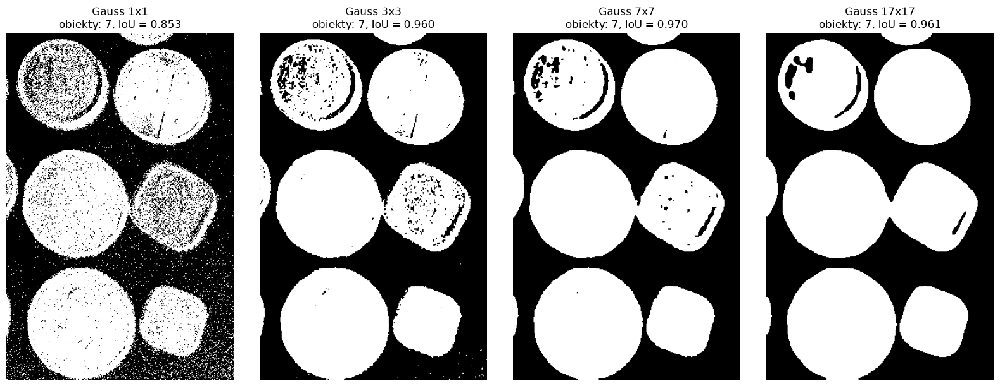

In [10]:
show_filtered_masks('Gauss')

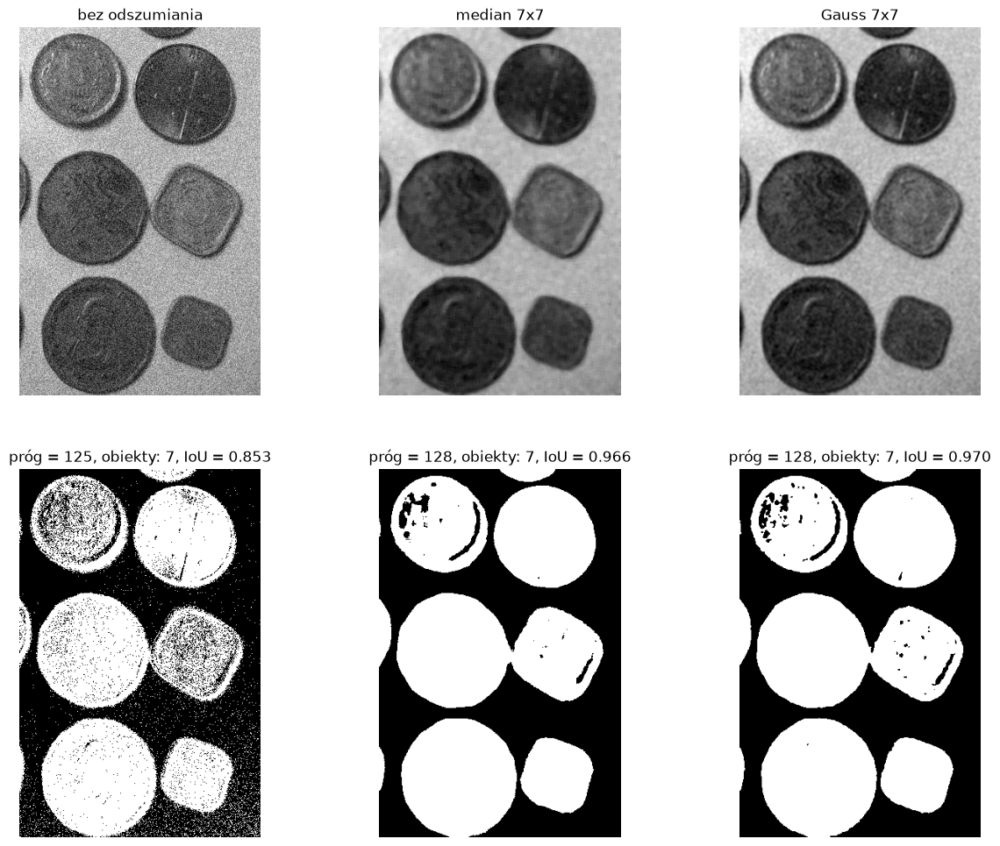

In [11]:
variants = {
    'bez odszumiania': noisy,
    'median 7x7': cv2.medianBlur(noisy, 7),
    'Gauss 7x7': cv2.GaussianBlur(noisy, (7, 7), 0),
}
_, axes = plt.subplots(2, len(variants), figsize=(15, 12))
for i, (name, img) in enumerate(variants.items()):
    t, mask = otsu_inv(img)
    axes[0, i].imshow(img, cmap='gray'); axes[0, i].set_title(name); axes[0, i].axis('off')
    axes[1, i].imshow(mask, cmap='gray'); axes[1, i].set_title(f'próg = {t:.0f}, obiekty: {count_objects(mask)}, IoU = {iou(mask, mask_otsu):.3f}'); axes[1, i].axis('off')
plt.show()

**Wnioski:**
- szum rozmywa piki histogramu, przez co dowolny próg daje "pieprz i sól" w tle i dziury w monetach
  (IoU z maską czystego obrazu tylko 0.853),
- filtr przed progowaniem przywraca dwumodalny histogram i próg Otsu wraca do ~128 (jak dla obrazu czystego),
- IoU rośnie do okna 7x7 (median 0.966, Gauss 0.970), a dla większych okien spada, bo rozmywają się
  krawędzie monet i zaczynają się one sklejać (od 13x13 liczba obiektów spada z 7 do 5) - wybrane 7x7,
- mediana lepiej zachowuje ostre krawędzie, Gauss daje gładsze wnętrza monet; różnica w IoU jest minimalna.

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

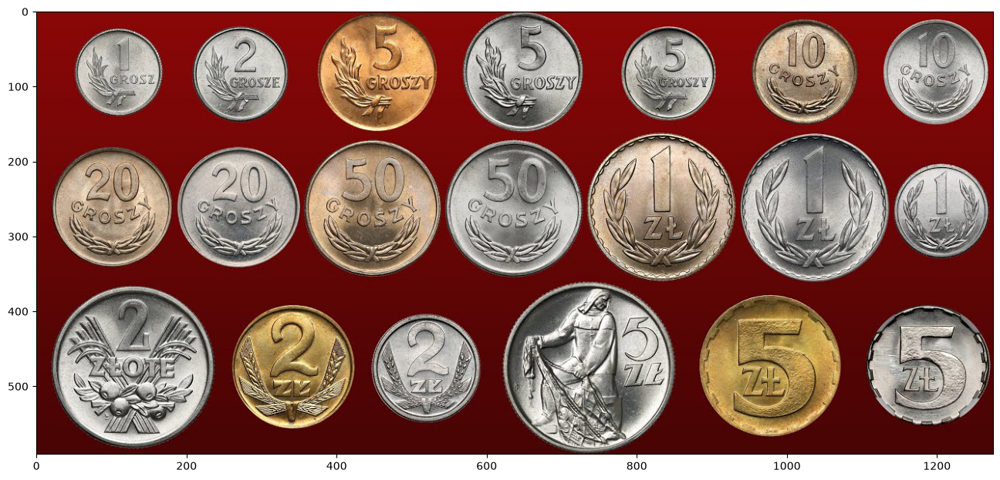

In [12]:
monety_kolor = cv2.imread('Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1]);

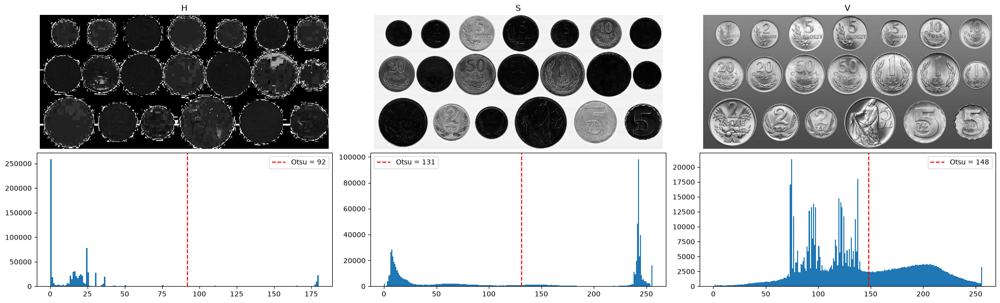

In [13]:
hsv = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)
CHANNELS = ['H', 'S', 'V']

_, axes = plt.subplots(2, 3, figsize=(20, 6), constrained_layout=True)
for i, name in enumerate(CHANNELS):
    t, _ = cv2.threshold(hsv[..., i], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    axes[0, i].imshow(hsv[..., i], cmap='gray'); axes[0, i].set_title(name); axes[0, i].axis('off')
    max_value = 180 if name == 'H' else 256   # H w OpenCV ma zakres 0-179
    axes[1, i].hist(hsv[..., i].ravel(), max_value, range=(0, max_value))
    axes[1, i].axvline(t, color='r', ls='--', label=f'Otsu = {t:.0f}'); axes[1, i].legend()
plt.show()

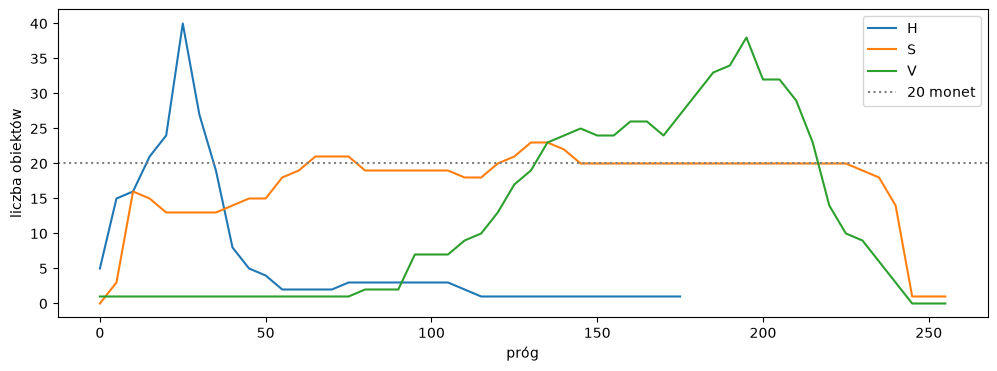

In [ ]:
sweep = np.arange(0, 256, 5)
sweep_h = sweep[sweep < 180]   # H w OpenCV ma zakres 0-179
plt.figure(figsize=(12, 4))
plt.plot(sweep_h, [count_objects(cv2.threshold(hsv[..., 0], t, 255, cv2.THRESH_BINARY)[1]) for t in sweep_h], label='H')
plt.plot(sweep, [count_objects(cv2.threshold(hsv[..., 1], t, 255, cv2.THRESH_BINARY_INV)[1]) for t in sweep], label='S')
plt.plot(sweep, [count_objects(cv2.threshold(hsv[..., 2], t, 255, cv2.THRESH_BINARY)[1]) for t in sweep], label='V')
plt.axhline(20, color='gray', ls=':', label='20 monet')
plt.xlabel('próg'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

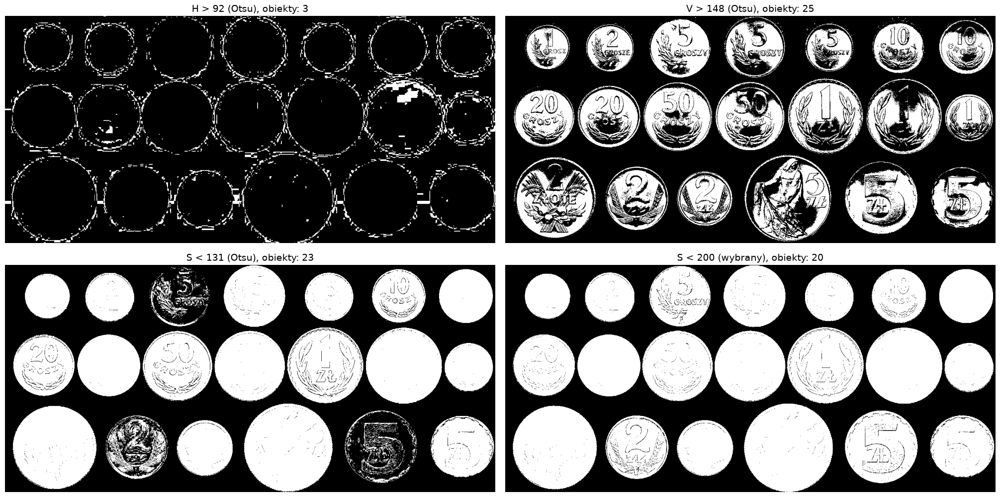

In [ ]:
S_THRESHOLD = 200
t_h, mask_h_otsu = cv2.threshold(hsv[..., 0], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_v, mask_v_otsu = cv2.threshold(hsv[..., 2], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_s, mask_s_otsu = cv2.threshold(hsv[..., 1], 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_, mask_color = cv2.threshold(hsv[..., 1], S_THRESHOLD, 255, cv2.THRESH_BINARY_INV)
masks = [(f'H > {t_h:.0f} (Otsu)', mask_h_otsu), (f'V > {t_v:.0f} (Otsu)', mask_v_otsu),
         (f'S < {t_s:.0f} (Otsu)', mask_s_otsu), (f'S < {S_THRESHOLD} (wybrany)', mask_color)]
_, axes = plt.subplots(2, 2, figsize=(20, 10), constrained_layout=True)
for ax, (name, mask) in zip(axes.ravel(), masks):
    ax.imshow(mask, cmap='gray'); ax.set_title(f'{name}, obiekty: {count_objects(mask)}', fontsize=14); ax.axis('off')
plt.show()

**Uzasadnienie:**
- H nie nadaje się: srebrne monety mają prawie zerowe nasycenie, więc ich odcień jest nieokreślony (szum),
  a czerwone tło leży na H ~ 0 i ~179 (odcień się zawija) - liczba obiektów dla żadnego progu nie jest stabilna,
- V nie nadaje się: tło ma gradient jasności, a monety refleksy - dla żadnego progu nie ma 20 obiektów,
- S rozdziela najlepiej: tło jest silnie nasycone (~240), srebrne monety prawie wcale, złote/miedziane ~150,
- liczba obiektów na S jest stabilna (20 monet) dla T = 145-225; próg Otsu (131) leży poniżej tego przedziału
  i gubi części złotych monet, dlatego wybrany jest próg T = 180 ze środka przedziału.

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

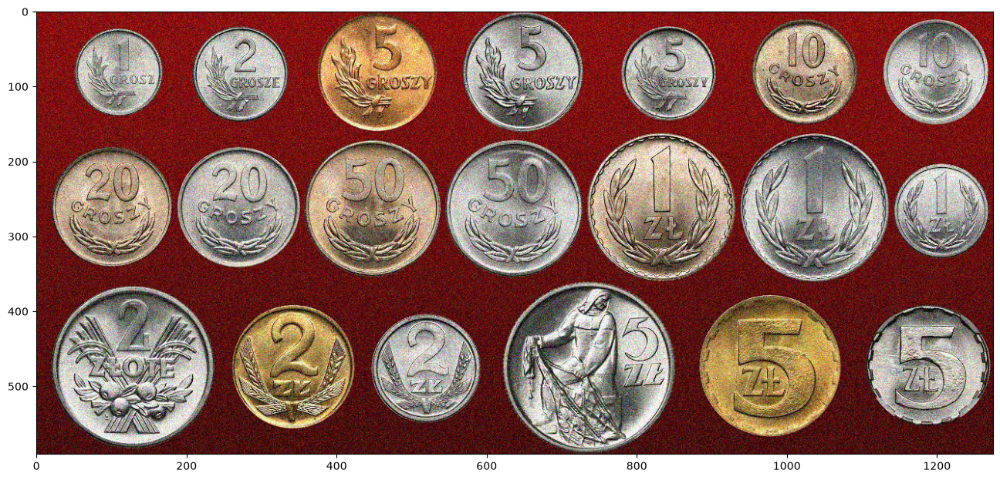

In [16]:
monety_kolor_szum = cv2.imread('Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

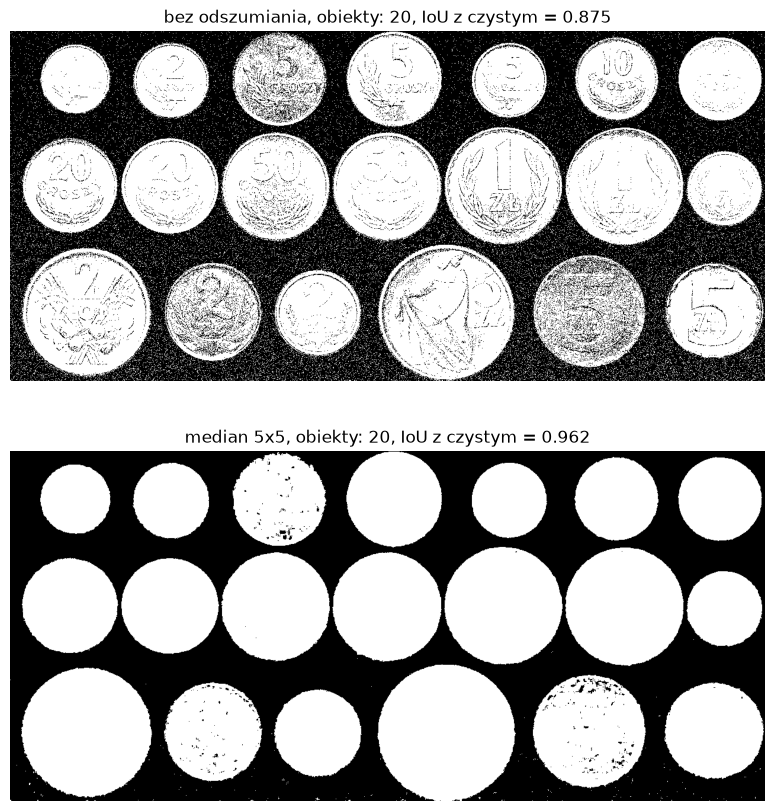

In [17]:
def binarize_color(img, threshold=S_THRESHOLD):
    s = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]
    return cv2.threshold(s, threshold, 255, cv2.THRESH_BINARY_INV)[1]

variants = {
    'bez odszumiania': monety_kolor_szum,
    'median 5x5': cv2.medianBlur(monety_kolor_szum, 5),
}
_, axes = plt.subplots(2, 1, figsize=(12, 10))
for ax, (name, img) in zip(axes, variants.items()):
    mask = binarize_color(img)
    ax.imshow(mask, cmap='gray'); ax.set_title(f'{name}, obiekty: {count_objects(mask)}, IoU z czystym = {iou(mask, mask_color):.3f}'); ax.axis('off')
plt.show()

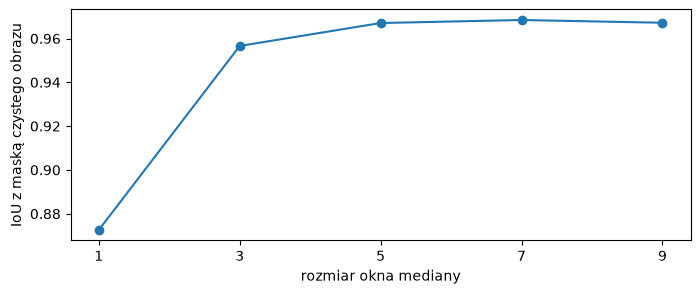

In [32]:
kernel_sizes = [1, 3, 5, 7, 9]
plt.figure(figsize=(8, 3))
plt.plot(kernel_sizes, [iou(binarize_color(cv2.medianBlur(monety_kolor_szum, k)), mask_color) for k in kernel_sizes], 'o-')
plt.xticks(kernel_sizes); plt.xlabel('rozmiar okna mediany'); plt.ylabel('IoU z maską czystego obrazu'); plt.show()

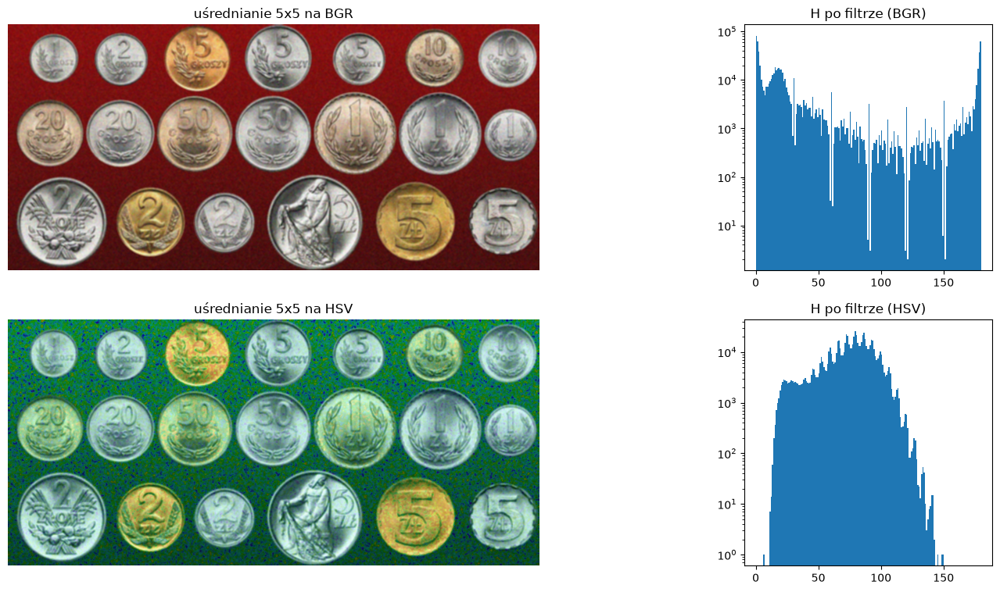

In [ ]:
hsv_noisy = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)

blur_bgr = cv2.blur(monety_kolor_szum, (5, 5))
blur_hsv = cv2.blur(hsv_noisy, (5, 5))
_, axes = plt.subplots(2, 2, figsize=(18, 9), gridspec_kw={'width_ratios': [3, 1]})
for row, (name, img, h) in enumerate([('uśrednianie 5x5 na BGR', blur_bgr, cv2.cvtColor(blur_bgr, cv2.COLOR_BGR2HSV)[..., 0]),
                                      ('uśrednianie 5x5 na HSV', cv2.cvtColor(blur_hsv, cv2.COLOR_HSV2BGR), blur_hsv[..., 0])]):
    axes[row, 0].imshow(img[..., ::-1]); axes[row, 0].set_title(name); axes[row, 0].axis('off')
    axes[row, 1].hist(h.ravel(), 180, range=(0, 180)); axes[row, 1].set_yscale('log'); axes[row, 1].set_title(f'H po filtrze ({name[-3:]})')
plt.show()

**Wnioski:**
- szum zmienia barwę pojedynczych pikseli: piksele tła o zaniżonym nasyceniu wpadają do maski, a w monetach
  powstają dziury - IoU z maską czystego obrazu spada do 0.875; liczba monet nadal wynosi 20 tylko dzięki
  odrzucaniu obiektów < 500 px, sama maska jest zaszumiona, a przedział stabilnych progów się zwęża (150-205),
- filtr medianowy przed konwersją do HSV przywraca jednolite nasycenie tła: IoU ~0.962 dla 5x5
  (7x7 daje to samo, 9x9 już mniej, bo rozmywa krawędzie monet), więc wybrane jest 5x5,
- odszumianie trzeba robić na BGR, nie na HSV: H jest kątem, a szum rozrzuca czerwone tło po obu końcach skali
  (H ~ 0-10 i H ~ 170-179); filtr uśredniający liczy zwykłą średnią, np. (0 + 178) / 2 = 89 (ok. 178°, cyjan),
  więc czerwone tło po filtrze na HSV staje się zielono-turkusowe - zmieniamy barwę, zamiast usuwać szum
  (S i V się nie zawijają, ale H już tak).

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

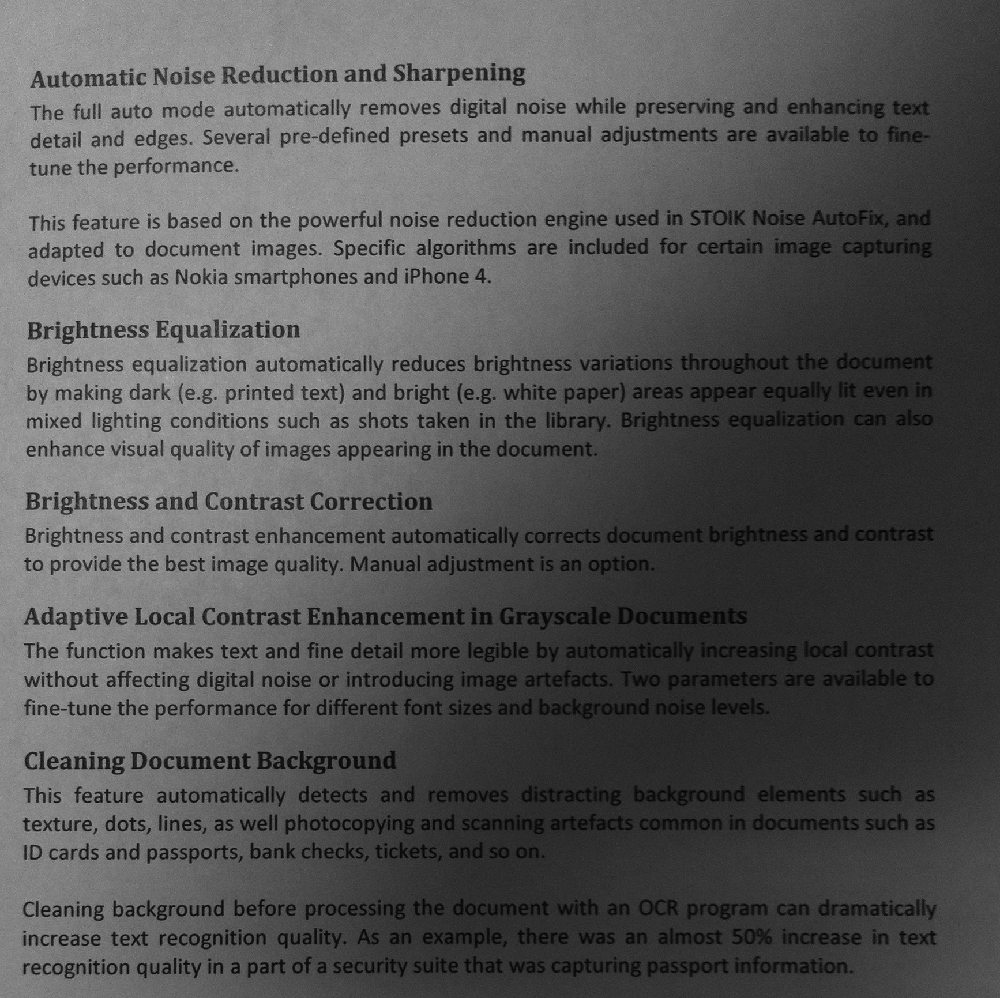

In [20]:
tekst = cv2.imread('Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

Rozwiązanie:

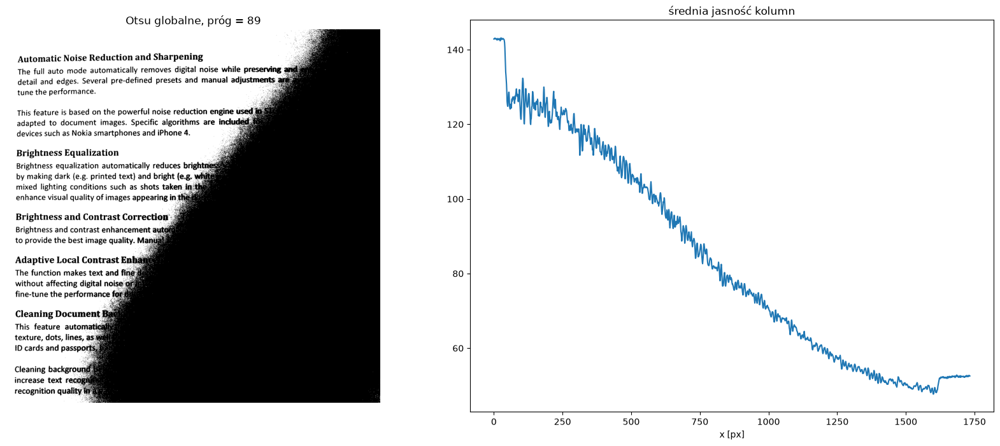

In [21]:
text_gray = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)

t_global, mask_global = cv2.threshold(text_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].imshow(mask_global, cmap='gray'); axes[0].set_title(f'Otsu globalne, próg = {t_global:.0f}'); axes[0].axis('off')
axes[1].plot(text_gray.mean(axis=0)); axes[1].set_title('średnia jasność kolumn'); axes[1].set_xlabel('x [px]')
plt.show()

**Globalne Otsu:**
- jasność kartki spada od ~140 po lewej do ~50 po prawej, więc tło po ciemnej stronie jest ciemniejsze niż litery po jasnej,
- próg Otsu (89) dobrze działa po lewej, ale cała prawa część strony za ukośną granicą cienia wychodzi czarna - tło i litery są tam poniżej progu,
- jeden próg dla całego obrazu nie wystarczy, trzeba go liczyć lokalnie.

In [ ]:
def local_otsu(gray, window, step, min_sep=0.3):
    h, w = gray.shape
    m = (window - step) // 2
    padded = cv2.copyMakeBorder(gray, m, m + window, m, m + window, cv2.BORDER_REFLECT)
    thr_map = np.zeros((h, w), np.float32)
    for y in range(0, h, step):
        for x in range(0, w, step):
            patch = padded[y:y + window, x:x + window]
            t, _ = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            dark, bright = patch[patch <= t], patch[patch > t]
            if (bright.mean() - dark.mean()) / bright.mean() < min_sep:
                t = 0
            thr_map[y:y + step, x:x + step] = t
    return np.where(gray > thr_map, 255, 0).astype(np.uint8)

**Jak działa `local_otsu`:**
- okno przesuwa się co `step` pikseli; dla każdego bloku `step x step` liczę próg Otsu z większego okna `window x window`, w którego środku leży ten blok,
- okno musi być większe od bloku, żeby zawierało i litery, i tło, a dzięki nakładaniu się okien próg zmienia się płynnie,
- obraz jest poszerzony odbiciem lustrzanym, żeby okna przy krawędziach też miały pełny rozmiar,
- `min_sep`: w oknie z samym papierem Otsu i tak dzieli piksele na dwie klasy (szum). Jeśli średnie obu klas różnią się względnie o mniej niż `min_sep`, uznaję okno za tło. Różnica jest liczona **względem jasności** (dzielona przez średnią jasnej klasy), bo w ciemnym rogu litery mają mały kontrast bezwzględny.

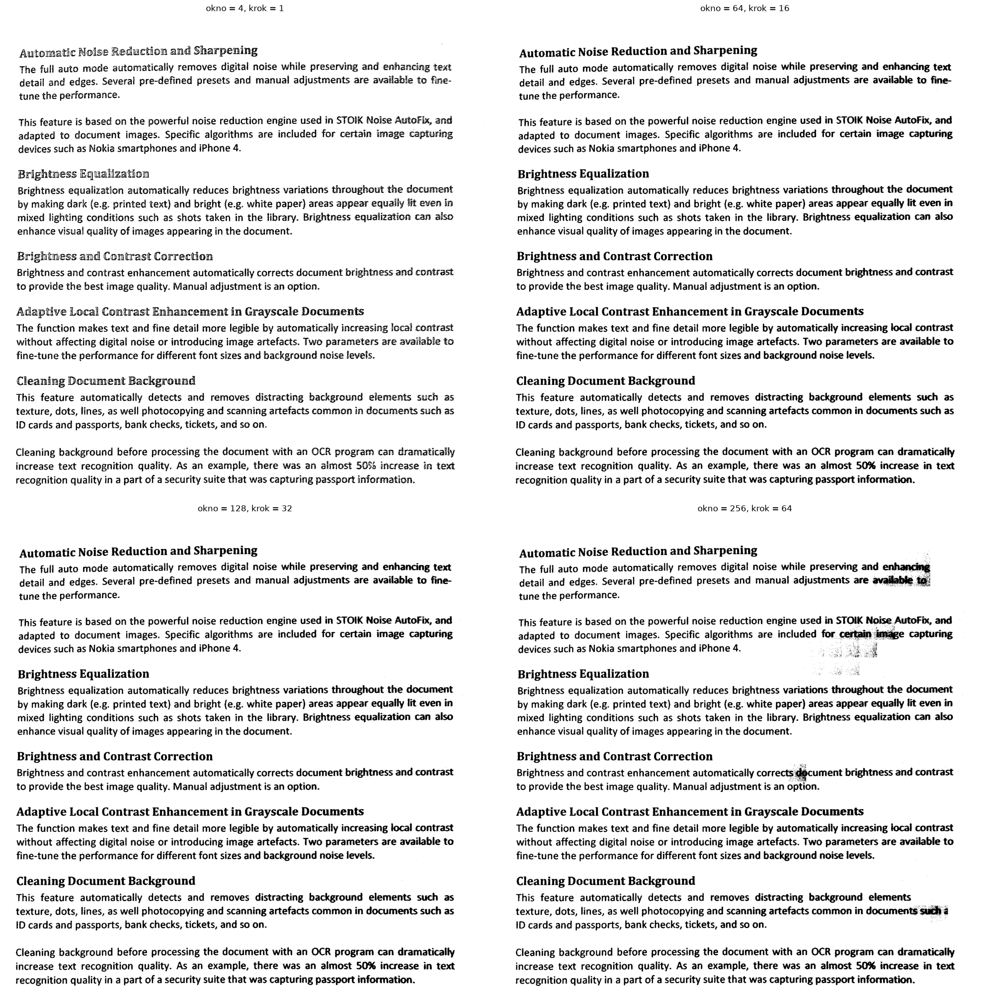

In [31]:
windows = [4, 64, 128, 256]
_, axes = plt.subplots(2, 2, figsize=(20, 20), constrained_layout=True)
for ax, window in zip(axes.ravel(), windows):
    ax.imshow(local_otsu(text_gray, window, window // 4), cmap='gray')
    ax.set_title(f'okno = {window}, krok = {window // 4}'); ax.axis('off')
plt.show()

**Wnioski - rozmiar okna:**
- 16, 64 i 128: tekst czytelny na całej stronie, także w ciemnym rogu. Okna bez liter odrzuca `min_sep`, więc nawet małe okno nie zostawia szumu w tle,
- małe okno jest jednak wolne: liczba okien rośnie jak (rozmiar obrazu / krok)², dla okna 16 to ~190 tys. wywołań Otsu,
- 256: okno jest za duże, oświetlenie zmienia się w jego środku i wracają problemy progu globalnego - na granicy cienia pojawiają się szare łaty, litery się rozlewają, a końcówki linii znikają ("text", "fine-", "such as"),
- okno musi być większe od litery (~20 px), ale dużo mniejsze od odległości, na której zmienia się oświetlenie (kilkaset px) - tutaj dobrze działa 64-128.

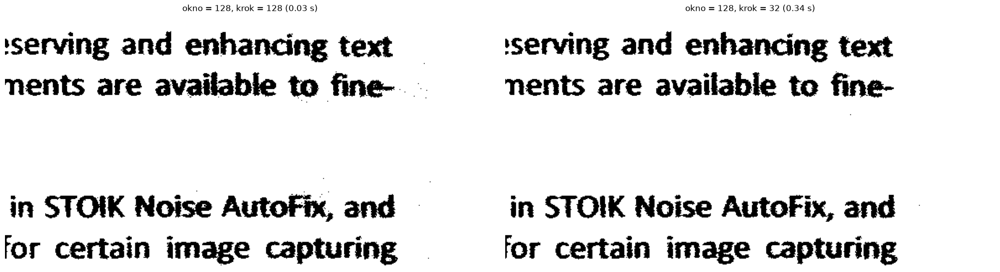

In [ ]:
import time

crop = np.s_[150:450, 1150:]
_, axes = plt.subplots(1, 2, figsize=(20, 6), constrained_layout=True)
for ax, step in zip(axes, [128, 32]):
    start = time.perf_counter()
    mask = local_otsu(text_gray, 128, step)
    ax.imshow(mask[crop], cmap='gray'); ax.axis('off')
    ax.set_title(f'okno = 128, krok = {step} ({time.perf_counter() - start:.2f} s)x')
plt.show()

**Wnioski - przesuwanie okna:**
- krok = okno (kafelki): cały kafelek dostaje jeden próg, także jego rogi daleko od środka okna, więc próg zmienia się skokowo na granicach kafelków. Puste części kafelka z tekstem dostają próg policzony dla liter i w tle pojawiają się kropki (za "fine-", nad "AutoFix, and"),
- krok = 1/4 okna (nakładanie): każdy blok dostaje próg z okna, w którego środku leży, więc próg zmienia się płynnie i tło jest prawie czyste,
- przy dobrym oknie różnica jest niewielka, a koszt rośnie jak 1/krok² - krok 1/4 okna to 16 razy więcej okien niż kafelki (0.33 s zamiast 0.03 s).

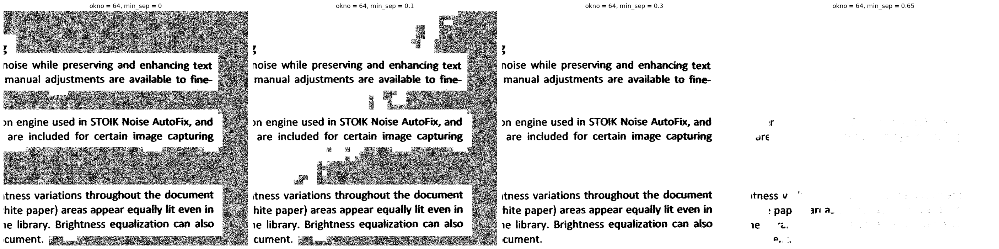

In [25]:
_, axes = plt.subplots(1, 4, figsize=(28, 8), constrained_layout=True)
for ax, s in zip(axes, [0, 0.1, 0.3, 0.65]):
    ax.imshow(local_otsu(text_gray, 64, 16, min_sep=s)[:800, 900:], cmap='gray')
    ax.set_title(f'okno = 64, min_sep = {s}'); ax.axis('off')
plt.show()

**Wnioski - `min_sep` (wycinek prawej górnej części):**
- 0 (bez sprawdzania): puste fragmenty kartki zamieniają się w szum, bo Otsu dzieli sam szum papieru na dwie klasy,
- 0.1: nadal duże łaty szumu - dla okien z samym papierem względna różnica klas to ~0.05-0.15, więc część z nich przechodzi,
- 0.3: tło czyste, tekst cały - dla okien z literami różnica to ~0.45-0.75, więc każda wartość pomiędzy (~0.15-0.45) działa tak samo,
- 0.65: za wysoko, okna z tekstem też są uznane za tło i tekst znika, najpierw w ciemnej części, gdzie kontrast liter jest najmniejszy.

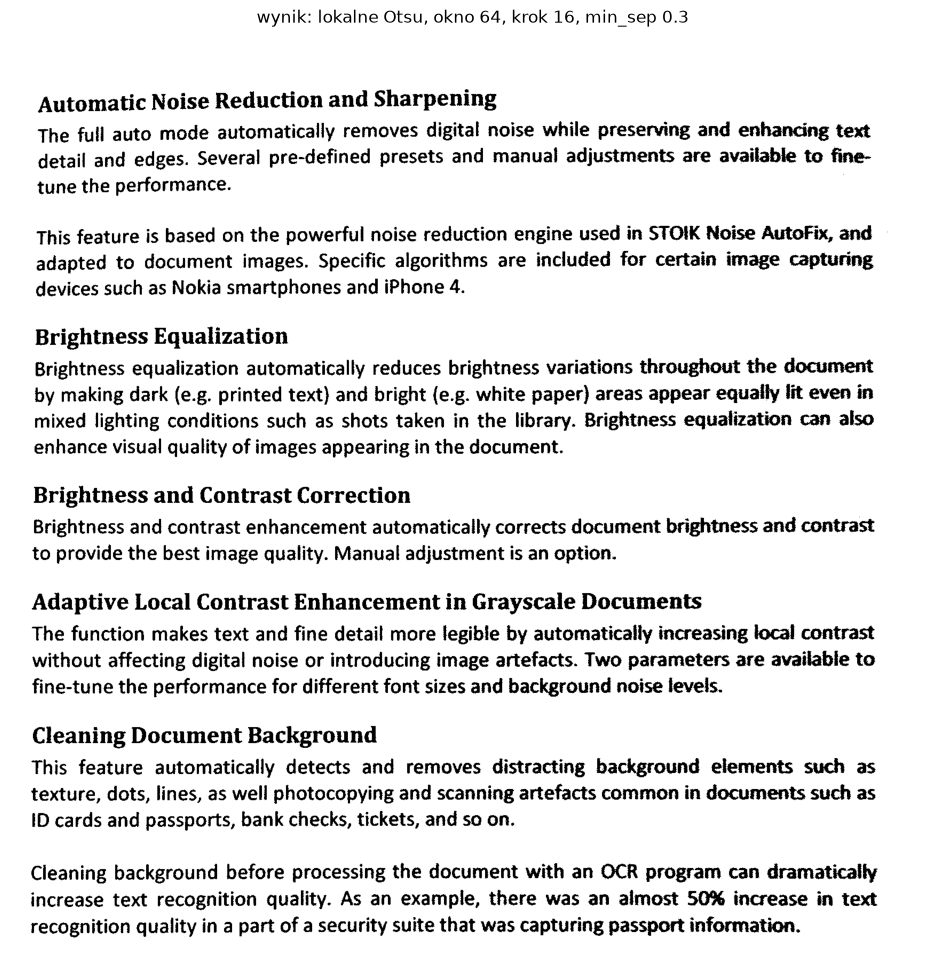

In [26]:
mask_text = local_otsu(text_gray, 64, 16)
plt.figure(figsize=(12, 12)); plt.imshow(mask_text, cmap='gray'); plt.title('wynik: lokalne Otsu, okno 64, krok 16, min_sep 0.3'); plt.axis('off'); plt.show()